## Import Library

In [ ]:
from transformers import BertTokenizerFast, BertForTokenClassification, Trainer, TrainingArguments, DataCollatorForTokenClassification, AutoTokenizer, AutoModelForTokenClassification, EarlyStoppingCallback
from datasets import load_dataset, Dataset, DatasetDict, load_from_disk

import os
import random
import evaluate
from collections import Counter, defaultdict
import matplotlib.pyplot as plt
from seqeval.metrics import classification_report
import pandas as pd
import numpy as np

folder_path = "dataset_conll/"

## Preparing Dataset

In [ ]:
def read_conll(path):
    tokens, tags = [], []

    with open(path, "r", encoding="utf-8") as f:
        # Loop every line
        for line in f:
            
            # Skip newline
            if line.strip() == "":
                continue
            
            # Split tokens and tags e.g -> Designer B-ROLE -> ['Designer', 'B-ROLE']
            splits = line.strip().split()
            
            # Skip weird lines e.g " O", where the expected lines e.g "Designer B-ROLE"
            if len(splits) < 2:
                continue
            
            # word = 'Designer', tag = 'B-ROLE'
            word, tag = splits[0], splits[-1]
            tokens.append(word)
            tags.append(tag)

    # Make sure both token and tags has same length
    assert len(tokens) == len(tags), f"Token-label mismatch: {len(tokens)} vs {len(tags)}"

    return tokens, tags


In [3]:
def load_all_cv(folder_path, train_ratio=0.7, val_ratio=0.15, seed=1):
    """Merge all documents in the folder and split into train/val/test"""
    random.seed(seed)

    data = []
    
    # Get all documents
    all_files = [f for f in os.listdir(folder_path) if f.endswith(".conll")]
    print(f"Total CV loaded: {len(all_files)}")
    print("======================================================")

    # Loop every document
    for i, filename in enumerate(sorted(all_files)):
        path = os.path.join(folder_path, filename)
        tokens, tags = read_conll(path)

        # Append to data (represent each document)
        data.append({
            "id": i,
            "doc_id": filename.replace(".conll", ""),
            "tokens": tokens,
            "ner_tags": tags
        })

    # Split by each resume, not sentence
    random.shuffle(data)
    n_total = len(data)
    n_train = int(train_ratio * n_total)
    n_val = int(val_ratio * n_total)

    train_data = data[:n_train]
    val_data = data[n_train:n_train + n_val]
    test_data = data[n_train + n_val:]
    
    print("Train data:", len(train_data))
    print("Val data  :", len(val_data))
    print("Test data :", len(test_data))
    print("======================================================")

    # Refactor to HuggingFace Dataset format
    dataset = DatasetDict({
        "train": Dataset.from_list(train_data),
        "validation": Dataset.from_list(val_data),
        "test": Dataset.from_list(test_data)
    })
    return dataset

In [4]:
dataset = load_all_cv(folder_path)
dataset

Total CV loaded: 513
Train data: 359
Val data  : 76
Test data : 78


DatasetDict({
    train: Dataset({
        features: ['id', 'doc_id', 'tokens', 'ner_tags'],
        num_rows: 359
    })
    validation: Dataset({
        features: ['id', 'doc_id', 'tokens', 'ner_tags'],
        num_rows: 76
    })
    test: Dataset({
        features: ['id', 'doc_id', 'tokens', 'ner_tags'],
        num_rows: 78
    })
})

In [5]:
dataset

DatasetDict({
    train: Dataset({
        features: ['id', 'doc_id', 'tokens', 'ner_tags'],
        num_rows: 359
    })
    validation: Dataset({
        features: ['id', 'doc_id', 'tokens', 'ner_tags'],
        num_rows: 76
    })
    test: Dataset({
        features: ['id', 'doc_id', 'tokens', 'ner_tags'],
        num_rows: 78
    })
})

In [38]:
dataset['train'][0]

{'id': 80,
 'doc_id': 'CV_171',
 'tokens': ['PRESENTATION',
  'DESIGNER',
  'Summary',
  'Customer',
  'Service',
  'and',
  'Retail',
  'Associate',
  '.',
  'Specializes',
  'in',
  'Design',
  'and',
  'technology',
  ',',
  'with',
  'a',
  'particular',
  'talent',
  'for',
  'building',
  'a',
  'solid',
  'customer',
  'base',
  '.',
  'Team-',
  'oriented',
  ',',
  'working',
  'well',
  'in',
  'a',
  'collaborative',
  'environment',
  ',',
  'yet',
  'thrives',
  'on',
  'personal',
  'sales',
  'achievements',
  'Highlights',
  'InfoGraphics',
  'Person',
  'of',
  'the',
  'Quater',
  '(',
  '2014',
  ')',
  'MTN',
  'Yello',
  'Star',
  'Award',
  'Person',
  'of',
  'the',
  'Quater',
  '.',
  'Customer',
  'Care',
  'Satisfaction',
  'Training',
  'Retail',
  'and',
  'Sales',
  'Adobe',
  'Photoshop',
  '(',
  'Mock',
  'ups',
  'and',
  'Prototype',
  ')',
  'Axure',
  'RP',
  '(',
  'Wireframes',
  'and',
  'Interactive',
  'Prototypes',
  ')',
  'Adobe',
  'Illustr

## Preprocessing

In [ ]:
bert_base = "bert-base-uncased"
# dslim_bert = "dslim/bert-base-NER" # additional kwargs, ignore_mismatched_sizes=True

hf_model = bert_base

In [ ]:
label_list = ['O', 'B-SKILL', 'I-SKILL', 'B-EXPERIENCE', 'I-EXPERIENCE', 'B-EDUCATION', 'I-EDUCATION']
label2id = {label: idx for idx, label in enumerate(label_list)}
id2label = {idx: label for label, idx in label2id.items()}

def load_model(hf_model, **model_kwargs):
    tokenizer = BertTokenizerFast.from_pretrained(hf_model)
    model = BertForTokenClassification.from_pretrained(hf_model,
        num_labels=len(label_list),
        id2label=id2label,
        label2id=label2id,
        **model_kwargs
        )
    
    return tokenizer, model

tokenizer, model = load_model(hf_model)

c:\Users\asus\anaconda3\envs\llms\Lib\site-packages\huggingface_hub\file_download.py:945: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of BertForTokenClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [8]:
# Show example word of our dataset
example_text = dataset['train'][0]["tokens"]
print("Example_ text    :", example_text)

# Tokenize the word into id, the length of tokenized id might be more than original text due to subword tokenization e.g 'playing' -> 'play', '##ing'
tokenized_input = tokenizer(example_text, is_split_into_words=True)
print("Tokenized input  :", tokenized_input)

# Conver back from id to token e.g id=1 -> 'play', id=2 -> '##ing'
tokens = tokenizer.convert_ids_to_tokens(tokenized_input["input_ids"])
print("Tokens           :", tokens)

# Map tokens with their ID to see which token belongs to which word, e.g 'playing' -> 'play' id=1, '##ing' id=1
word_ids = tokenized_input.word_ids()
print("Word IDs         :", word_ids)

Example_ text    : ['PRESENTATION', 'DESIGNER', 'Summary', 'Customer', 'Service', 'and', 'Retail', 'Associate', '.', 'Specializes', 'in', 'Design', 'and', 'technology', ',', 'with', 'a', 'particular', 'talent', 'for', 'building', 'a', 'solid', 'customer', 'base', '.', 'Team-', 'oriented', ',', 'working', 'well', 'in', 'a', 'collaborative', 'environment', ',', 'yet', 'thrives', 'on', 'personal', 'sales', 'achievements', 'Highlights', 'InfoGraphics', 'Person', 'of', 'the', 'Quater', '(', '2014', ')', 'MTN', 'Yello', 'Star', 'Award', 'Person', 'of', 'the', 'Quater', '.', 'Customer', 'Care', 'Satisfaction', 'Training', 'Retail', 'and', 'Sales', 'Adobe', 'Photoshop', '(', 'Mock', 'ups', 'and', 'Prototype', ')', 'Axure', 'RP', '(', 'Wireframes', 'and', 'Interactive', 'Prototypes', ')', 'Adobe', 'Illustrator', '(', 'Vector', 'Assets', ')', 'Adobe', 'Dreamweaver', '(', 'Creation', 'of', 'mobile', 'sites', 'and', 'Websites', ')', 'HTML', 'and', 'CSS', '.', 'Adobe', 'Creative', 'Suite', 'CC', ',

Sometimes after we do tokenize, the number of tokens before and after are totally different (usually after tokenized has more tokens than before) it is caused sometimes tokenizer

This will caused ambiguity for our NER tags because number of `Input id` != `NER token`

In [9]:
print("Number of NER Tags : ", len(dataset["train"][0]["ner_tags"]))
print("Number of tokenized_input :", len(tokenized_input["input_ids"]))

Number of NER Tags :  203
Number of tokenized_input : 241


So in this case we need to perform `Token-Alignment` to make sure NER tags belongs to correct word id


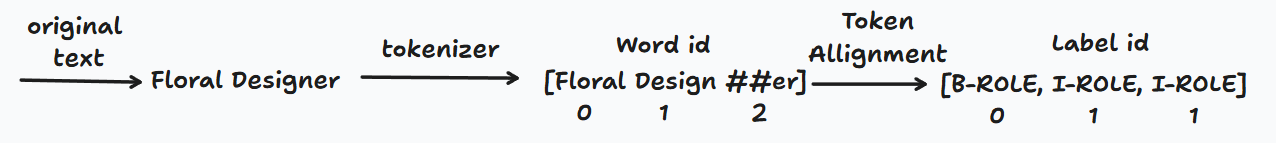

In this case BERT base limitation with only 512 tokens 

In [10]:
def allign_label(labels, word_ids, label_all_tokens=True):
    """
    Align the original word-level labels to the tokenized input labels.
    
    e.g if the sentence floral designer flower has labels [B-ROLE, I-ROLE, O]
    when we use tokenizer, our word id become floral design ##er flower but our labels are still [B-ROLE, I-ROLE, O], (expected [B-ROLE, I-ROLE, I-ROLE, O])
    This function will make it allign into [B-ROLE, I-ROLE, I-ROLE, O]
    
    """
    aligned_labels = []
    previous_word_idx = None
    for word_idx in word_ids:
        if word_idx is None:
            aligned_labels.append(-100)  # for [CLS], [SEP] tokens we set to -100
        elif word_idx != previous_word_idx:
            aligned_labels.append(labels[word_idx])  # first token of a word
        else:
            aligned_labels.append(labels[word_idx] if label_all_tokens else -100)  # second token of a word
        previous_word_idx = word_idx
    return aligned_labels

In [11]:
def tokenize_and_align_labels(dataset):
    """Tokenize input and align the labels for NER task, handling overflow for long documents."""
    # In this case, we applied windows sliding for tokenizer to handle long documents
    tokenized_inputs = tokenizer(
        dataset["tokens"],
        is_split_into_words=True,    # indicate that input is already a list of tokens
        truncation=True,             # cut off if longer than max_length
        padding=False,               # padding handled later by DataCollator
        max_length=512,              # BERT maximum sequence length
    )
    
    all_labels = []

    # Iterate over each tokenized chunk
    for i in range(len(tokenized_inputs["input_ids"])):
        # Get word indices for the current chunk (maps subwords back to original words)
        word_ids = tokenized_inputs.word_ids(i)
    
        # Retrieve NER labels (word-level) for the corresponding document
        word_labels = dataset["ner_tags"][i]

        # Convert label strings (e.g., "B-ROLE") to numeric IDs
        labels = [label2id[tag] for tag in word_labels]

        # Align word-level labels to subword-level tokens
        aligned_labels = allign_label(labels, word_ids)
        all_labels.append(aligned_labels)

    # Add aligned labels to the tokenized outputs
    tokenized_inputs["labels"] = all_labels
    return tokenized_inputs

In [12]:
tokenized_datasets = dataset.map(
    tokenize_and_align_labels,
    batched=True,
    remove_columns=dataset["train"].column_names, # remove unnecessary columns
)

Map:   0%|          | 0/359 [00:00<?, ? examples/s]

Map:   0%|          | 0/76 [00:00<?, ? examples/s]

Map:   0%|          | 0/78 [00:00<?, ? examples/s]

In [42]:
dataset

DatasetDict({
    train: Dataset({
        features: ['id', 'doc_id', 'tokens', 'ner_tags'],
        num_rows: 359
    })
    validation: Dataset({
        features: ['id', 'doc_id', 'tokens', 'ner_tags'],
        num_rows: 76
    })
    test: Dataset({
        features: ['id', 'doc_id', 'tokens', 'ner_tags'],
        num_rows: 78
    })
})

In [13]:
tokenized_datasets

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 359
    })
    validation: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 76
    })
    test: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 78
    })
})

Normal tokenizer_input has 3 keys:
- input_ids -> out token id
- token_type_ids -> focus on segmenting active token on sentence
- attention mask -> the way BERT know it's real token or padding token

After alignment and tokenize process, we add 1 more `labels` key as token of NER tags

In [14]:
# check if our train data input id has the same number as labels
for token, label in zip(tokenizer.convert_ids_to_tokens(tokenized_datasets["train"]["input_ids"][0]),tokenized_datasets["train"]["labels"][0]): 
    print(f"{token:_<20} {label}") 

[CLS]_______________ -100
presentation________ 3
designer____________ 4
summary_____________ 0
customer____________ 0
service_____________ 0
and_________________ 0
retail______________ 0
associate___________ 0
.___________________ 0
specializes_________ 0
in__________________ 0
design______________ 0
and_________________ 0
technology__________ 0
,___________________ 0
with________________ 0
a___________________ 0
particular__________ 0
talent______________ 0
for_________________ 0
building____________ 0
a___________________ 0
solid_______________ 0
customer____________ 0
base________________ 0
.___________________ 0
team________________ 0
-___________________ 0
oriented____________ 0
,___________________ 0
working_____________ 0
well________________ 0
in__________________ 0
a___________________ 0
collaborative_______ 0
environment_________ 0
,___________________ 0
yet_________________ 0
thrive______________ 0
##s_________________ 0
on__________________ 0
personal____________ 0
sales___

## Set up Trainer

In [15]:
# Data collector makes sure that during batching, the sequences are padded to the same length and labels are handled correctly
data_collator = DataCollatorForTokenClassification(tokenizer)

In [18]:
# Callbacks (EarlyStopping)

early_stopping = EarlyStoppingCallback(
    early_stopping_patience=5,
    early_stopping_threshold=0.01
)

In [20]:
# Define training arguments
training_args = TrainingArguments(
    output_dir="./results",
    evaluation_strategy="epoch",
    save_strategy="epoch",
    learning_rate=1e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=50,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    logging_dir="./logs",
)

In [21]:
# Metrics seqeval
metric = evaluate.load("seqeval")

In [22]:
def compute_metrics(p):
    # p = tuple from Trainer after epoch: (predictions, labels)
    predictions, labels = p
    predictions_idx = np.argmax(predictions, axis=2)  # get index with highest probability score

    # conver label id to label string
    true_labels = [
        [id2label[label_id] for label_id in label if label_id != -100]
        for label in labels
    ]
    
    # convert prediction label id into label string
    predictions_label = [
        [id2label[pred_id] for pred_id, label_id in zip(pred, label) if label_id != -100]
        for pred, label in zip(predictions_idx, labels)
    ]

    # compute results
    results = metric.compute(predictions=predictions_label, references=true_labels)

    # Pilih hasil yang mau kamu log
    return {
        "precision": results["overall_precision"],
        "recall": results["overall_recall"],
        "f1": results["overall_f1"],
        "accuracy": results["overall_accuracy"],
    }


In [23]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    tokenizer=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[early_stopping]
)

In [24]:
trainer.train()

  0%|          | 0/1150 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

c:\Users\asus\anaconda3\envs\llms\Lib\site-packages\seqeval\metrics\v1.py:57: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
c:\Users\asus\anaconda3\envs\llms\Lib\site-packages\seqeval\metrics\v1.py:57: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


{'eval_loss': 0.7239402532577515, 'eval_precision': 0.0, 'eval_recall': 0.0, 'eval_f1': 0.0, 'eval_accuracy': 0.7656765676567657, 'eval_runtime': 10.8369, 'eval_samples_per_second': 7.013, 'eval_steps_per_second': 0.461, 'epoch': 1.0}


  0%|          | 0/5 [00:00<?, ?it/s]

...

  0%|          | 0/5 [00:00<?, ?it/s]

{'eval_loss': 0.15547078847885132, 'eval_precision': 0.8091058694459682, 'eval_recall': 0.8438215102974829, 'eval_f1': 0.8260991318958275, 'eval_accuracy': 0.9529268716345318, 'eval_runtime': 10.1379, 'eval_samples_per_second': 7.497, 'eval_steps_per_second': 0.493, 'epoch': 14.0}


  0%|          | 0/5 [00:00<?, ?it/s]

{'eval_loss': 0.15838788449764252, 'eval_precision': 0.7851282051282051, 'eval_recall': 0.8758581235697941, 'eval_f1': 0.8280151433207139, 'eval_accuracy': 0.9506687510856349, 'eval_runtime': 12.3477, 'eval_samples_per_second': 6.155, 'eval_steps_per_second': 0.405, 'epoch': 15.0}
{'train_runtime': 2495.7167, 'train_samples_per_second': 7.192, 'train_steps_per_second': 0.461, 'train_loss': 0.25046395564424817, 'epoch': 15.0}


TrainOutput(global_step=345, training_loss=0.25046395564424817, metrics={'train_runtime': 2495.7167, 'train_samples_per_second': 7.192, 'train_steps_per_second': 0.461, 'total_flos': 1169852943099852.0, 'train_loss': 0.25046395564424817, 'epoch': 15.0})

In [25]:
predictions, labels, _ = trainer.predict(tokenized_datasets["test"])
predictions = np.argmax(predictions, axis=2)

for i in range(10):  
    pred_tags = [id2label[p] for (p, l) in zip(predictions[i], labels[i]) if l != -100]
    true_tags = [id2label[l] for l in labels[i] if l != -100]
    
    print(f"\nSample {i}:")
    print("Tokens :", tokenizer.convert_ids_to_tokens(tokenized_datasets["test"]["input_ids"][i]))
    print("TRUE :", true_tags)
    print("PRED :", pred_tags)

  0%|          | 0/5 [00:00<?, ?it/s]


Sample 0:
Tokens : ['[CLS]', 'information', 'technology', 'manager', 'experience', '04', '/', '2013', 'to', 'current', 'information', 'technology', 'manager', 'company', 'name', 'i', '##¼', 'city', ',', 'state', '08', '/', '1987', 'to', '06', '/', '2012', 'network', 'analyst', 'company', 'name', 'i', '##¼', 'city', ',', 'state', '02', '/', '1753', 'designer', '/', 'draft', '##er', 'company', 'name', 'i', '##¼', 'city', ',', 'state', 'plant', 'manager', '/', 'quality', 'control', 'manager', 'company', 'name', 'i', '##¼', 'city', ',', 'state', 'draft', '##er', 'company', 'name', 'i', '##¼', 'city', ',', 'state', 'education', 'master', 'of', 'science', ':', 'leadership', 'master', 'of', 'science', ':', 'information', 'systems', 'management', 'project', 'management', 'bachelor', 'of', 'science', ':', 'information', 'systems', 'management', 'mechanical', 'engineering', 'skills', 'anti', '-', 'virus', ',', 'backup', ',', 'cab', '##ling', ',', 'cisco', ',', 'hardware', ',', 'contracts', ',',

## Evaluation

In [ ]:
predictions = trainer.predict(tokenized_datasets["test"])

  0%|          | 0/5 [00:00<?, ?it/s]

In [31]:
print(predictions)

PredictionOutput(predictions=array([[[ 1.4854021e+00,  1.0104887e-01, -8.9715832e-01, ...,
         -6.9516772e-01, -2.8523979e-01, -1.5240957e-01],
        [-5.1311988e-01, -1.2575263e+00, -2.0446990e+00, ...,
         -4.7864336e-01, -1.3121721e+00, -1.8297167e+00],
        [-8.6211628e-01, -2.0671315e+00, -8.0284584e-01, ...,
          6.6419034e+00, -1.4607919e+00, -9.4466913e-01],
        ...,
        [-1.0000000e+02, -1.0000000e+02, -1.0000000e+02, ...,
         -1.0000000e+02, -1.0000000e+02, -1.0000000e+02],
        [-1.0000000e+02, -1.0000000e+02, -1.0000000e+02, ...,
         -1.0000000e+02, -1.0000000e+02, -1.0000000e+02],
        [-1.0000000e+02, -1.0000000e+02, -1.0000000e+02, ...,
         -1.0000000e+02, -1.0000000e+02, -1.0000000e+02]],

       [[ 2.3147774e+00,  1.3129574e-01, -6.9537205e-01, ...,
         -2.9751083e-01, -1.0697762e+00, -1.3516887e+00],
        [-8.7049383e-01, -8.9056987e-01, -2.1865218e+00, ...,
         -3.6647803e-01, -1.1822616e+00, -1.7814525e+0

In [ ]:
logits = predictions.predictions # predictions probability
labels = predictions.label_ids  # ground truth

preds = np.argmax(logits, axis=-1)

In [ ]:
# (rows, token per row, label_probability)
logits.shape

(78, 464, 7)

In [ ]:
# E.g for first CV and the first words, we can see the probability of each label
logits[0][0]

array([ 1.4854021 ,  0.10104887, -0.8971583 ,  0.63157994, -0.6951677 ,
       -0.2852398 , -0.15240957], dtype=float32)

In [77]:
np.argmax(logits, axis = -1)[0]

array([0, 3, 4, 4, 0, 0, 0, 0, 0, 0, 3, 4, 4, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 3, 4, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 3, 4, 4, 4, 0,
       0, 0, 0, 0, 0, 0, 3, 4, 4, 4, 4, 4, 0, 0, 0, 0, 0, 0, 0, 3, 3, 0,
       0, 0, 0, 0, 0, 0, 0, 5, 6, 6, 6, 6, 5, 6, 6, 6, 6, 6, 6, 6, 6, 5,
       6, 6, 6, 6, 6, 6, 6, 6, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 1, 2, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       1, 0, 0, 0, 1, 2, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 6, 0, 0, 0, 0, 6, 6, 6, 6, 0, 6, 0, 6, 6, 6, 0, 6,
       6, 6, 0, 0, 0, 0, 0, 0, 0, 5, 6, 6, 6, 6, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

In [78]:
print(preds.shape)
print(labels.shape)

(78, 464)
(78, 464)


In [ ]:
true_labels = []
true_preds = []

for pred, label in zip(preds, labels):
    # for every CV  
    curr_true_labels = []
    curr_true_preds = []
    for p, l in zip(pred, label):
        # for every token in CV
        
        if l != -100:  # ignore padding
            curr_true_labels.append(id2label[l])
            curr_true_preds.append(id2label[p])
    true_labels.append(curr_true_labels)
    true_preds.append(curr_true_preds)


In [81]:
print(true_labels[0])
print(true_preds[0])

['B-EXPERIENCE', 'I-EXPERIENCE', 'I-EXPERIENCE', 'O', 'O', 'O', 'O', 'O', 'O', 'B-EXPERIENCE', 'I-EXPERIENCE', 'I-EXPERIENCE', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'B-EXPERIENCE', 'I-EXPERIENCE', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'B-EXPERIENCE', 'I-EXPERIENCE', 'I-EXPERIENCE', 'I-EXPERIENCE', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'B-EXPERIENCE', 'I-EXPERIENCE', 'I-EXPERIENCE', 'I-EXPERIENCE', 'I-EXPERIENCE', 'I-EXPERIENCE', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'B-EDUCATION', 'I-EDUCATION', 'I-EDUCATION', 'I-EDUCATION', 'I-EDUCATION', 'B-EDUCATION', 'I-EDUCATION', 'I-EDUCATION', 'I-EDUCATION', 'I-EDUCATION', 'I-EDUCATION', 'I-EDUCATION', 'I-EDUCATION', 'I-EDUCATION', 'B-EDUCATION', 'I-EDUCATION', 'I-EDUCATION', 'I-EDUCATION', 'I-EDUCATION', 'I-EDUCATION', 'I-EDUCATION', 'I-EDUCATION', 'I-EDUCATION', 'O', 'O', 'O', 'O', 'O', 'B-SKILL', 'O', 'B-SKILL', 'B-SKILL', 'O', 'B-SKILL', 'O', 'O', 'O', 'O

In [ ]:
print(classification_report(true_labels, true_preds, digits=4))


              precision    recall  f1-score   support

   EDUCATION     0.9110    0.9048    0.9078       147
  EXPERIENCE     0.8872    0.9129    0.8999       448
       SKILL     0.7415    0.8588    0.7959      1353

   micro avg     0.7838    0.8747    0.8268      1948
   macro avg     0.8466    0.8922    0.8679      1948
weighted avg     0.7878    0.8747    0.8283      1948

